# 02 · Evaluation, visualisation and interpretability (Sachin)

Phase 1 (classical ML) results for Next Day Wildfire Spread (Huot et al., 2022).

**Inputs** (made by teammates' scripts, not by this notebook):
- `reports/preds/{model}.npz`: `y_true` and `y_prob`, each of shape (1689, 64, 64), one map per test patch,
  in the same order as `load_split("test")`. Labels are 1 = fire, 0 = no fire, -1 = unknown.
- `reports/results.csv`: test metrics per model from `src/evaluate.py`. `threshold` was chosen on the **eval** split.
- `reports/best_params.json`: hyperparameters of the tuned XGBoost / LightGBM.

**Rule used everywhere:** pixels with label -1 are dropped before any metric or plot.

**Outputs:** `reports/figures/eval_*.png` and `reports/results_table.md`.

In [1]:
import os
from pathlib import Path

# The notebook lives in notebooks/; move to the repo root so `src` imports and relative paths work.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np                    # arrays and maths
import pandas as pd                   # tables
import matplotlib.pyplot as plt       # plots
from sklearn.metrics import precision_recall_curve, roc_curve   # points of the PR and ROC curves

SEED = 0                              # team rule: every random choice uses seed 0
PREDS = Path("reports/preds")         # saved test predictions of the 6 models (from Harshil / Sushant)
FIGS = Path("reports/figures")        # where every figure of this notebook is saved
FIGS.mkdir(parents=True, exist_ok=True)   # create the folder if it does not exist yet

# Model name in files -> label shown in plots. Order = baselines first, tuned models last.
MODELS = {
    "persistence": "Persistence",
    "logreg_raw": "Logistic reg. (raw)",
    "rf_raw": "Random forest (raw)",
    "xgb_raw": "XGBoost (raw)",
    "xgboost": "XGBoost (tuned, all features)",
    "lightgbm": "LightGBM (tuned, all features)",
}
# Fixed colour per model (colour-blind-checked palette), dashed = baseline, solid = our tuned models.
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#6250d6"]))
STYLE = {m: "-" if m in ("xgboost", "lightgbm") else "--" for m in MODELS}

# Same look for every figure: sharp saved images, no top/right frame lines, light grid.
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

# Test metrics of all 6 models (made by src/evaluate.py); one row per model, looked up by name.
results = pd.read_csv("reports/results.csv").set_index("model")
results

,pr_auc,roc_auc,precision,recall,f1,threshold,best_f1,best_f1_threshold,recall_at_1fpr,recall_at_5fpr,n_pixels,fire_rate
model,,,,,,,,,,,,
persistence,0.1065,0.6333,0.3572,0.2728,0.3093,0.5000,0.3093,1.0000,0.2728,0.2728,6727699,0.0125
logreg_raw,0.1457,0.7985,0.3776,0.2658,0.3120,0.9358,0.3128,0.9262,0.2813,0.3190,6727699,0.0125
rf_raw,0.1565,0.8163,0.3712,0.2699,0.3125,0.8474,0.3141,0.8804,0.2785,0.3622,6727699,0.0125
xgb_raw,0.1455,0.7955,0.3373,0.2570,0.2917,0.8744,0.2962,0.9053,0.2666,0.3752,6727699,0.0125
xgboost,0.2565,0.9058,0.2425,0.5264,0.3321,0.9152,0.3579,0.9529,0.3884,0.6752,6727699,0.0125
lightgbm,0.2483,0.9030,0.2425,0.5198,0.3307,0.9166,0.3549,0.9505,0.3840,0.6707,6727699,0.0125


In [2]:
def load_preds(name):
    """Return y_true and y_prob maps (1689, 64, 64) for one model."""
    d = np.load(PREDS / f"{name}.npz")
    return d["y_true"], d["y_prob"]


# All models were scored on the same test pixels, so we read the labels once.
y_map, _ = load_preds("xgboost")
labelled = y_map != -1                      # mask of pixels we are allowed to score
y_flat = y_map[labelled].astype(int)        # 1-D vector of 0/1 labels
probs = {m: load_preds(m)[1][labelled] for m in MODELS}   # 1-D probabilities, same order as y_flat

fire_rate = y_flat.mean()                   # mean of 0/1 labels = share of fire pixels
print(f"test pixels: {y_map.size:,} | labelled: {labelled.sum():,} | dropped (-1): {(~labelled).sum():,}")
print(f"next-day fire rate among labelled pixels: {fire_rate:.4f}  (about 1 fire pixel in {1 / fire_rate:.0f})")

test pixels: 6,918,144 | labelled: 6,727,699 | dropped (-1): 190,445
next-day fire rate among labelled pixels: 0.0125  (about 1 fire pixel in 80)


## 1 · Precision-recall and ROC curves (test split)

**Why PR first.** Only 1.25% of labelled test pixels burn. ROC uses the false positive rate FP / (all no-fire pixels);
with 79 no-fire pixels per fire pixel, a model can raise many false alarms while FPR stays small, so ROC AUC looks good.
Precision = TP / (TP + FP) is hit directly by those false alarms, so PR AUC is the main metric here
(as in Huot et al. 2022). A random model gets PR AUC ≈ fire rate (0.0125) but ROC AUC = 0.5.

PR AUC is computed as average precision (`average_precision_score`), the same number as in `results.csv`.
The dot on each PR curve is the operating point at the threshold chosen on the **eval** split (best eval F1),
i.e. what the model would actually do on unseen data.

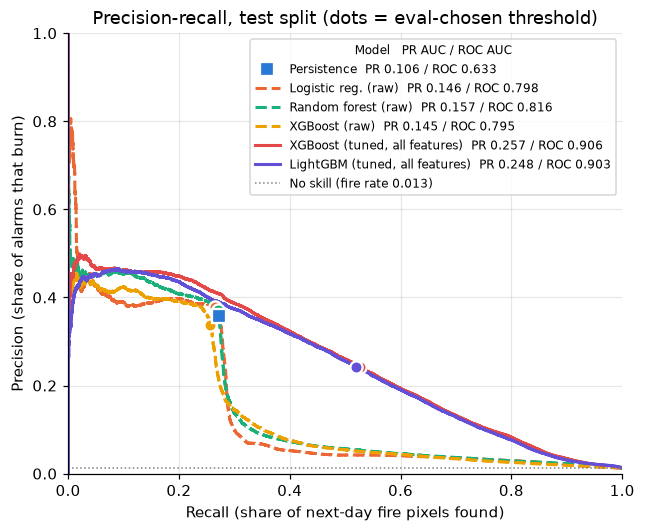

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for m, label in MODELS.items():
    r = results.loc[m]                         # this model's row of results.csv
    legend = f"{label}  PR {r.pr_auc:.3f} / ROC {r.roc_auc:.3f}"
    if m == "persistence":
        # Persistence outputs only 0 or 1, so it has ONE operating point, not a curve
        # (a straight line between PR points would overstate it).
        ax.plot(r.recall, r.precision, "s", ms=9, color=COLORS[m], mec="white", mew=1.5, zorder=6, label=legend)
        continue
    # sklearn tries every possible threshold and returns precision and recall at each one -> the curve
    precision, recall, _ = precision_recall_curve(y_flat, probs[m])
    ax.plot(recall, precision, STYLE[m], color=COLORS[m], lw=2, label=legend)
    # Operating point at the eval-chosen threshold (precision/recall columns of results.csv).
    ax.plot(r.recall, r.precision, "o", ms=8, color=COLORS[m], mec="white", mew=1.5, zorder=5)

# A model that guesses at random has precision = fire rate at every recall: the "no skill" line.
ax.axhline(fire_rate, color="grey", lw=1, ls=":", label=f"No skill (fire rate {fire_rate:.3f})")
ax.set(xlabel="Recall (share of next-day fire pixels found)", ylabel="Precision (share of alarms that burn)",
       xlim=(0, 1), ylim=(0, 1), title="Precision-recall, test split (dots = eval-chosen threshold)")
ax.legend(fontsize=8, loc="upper right", title="Model   PR AUC / ROC AUC", title_fontsize=8)
fig.savefig(FIGS / "eval_pr_curves.png")
plt.show()

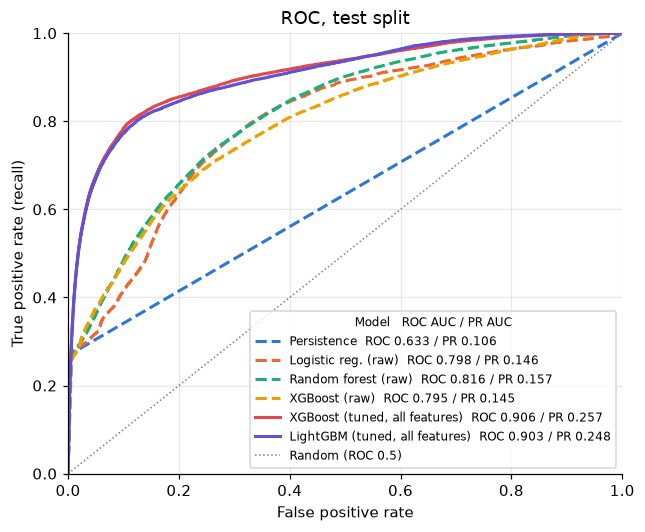

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for m, label in MODELS.items():
    # ROC curve: false positive rate (x) and true positive rate = recall (y) at every threshold
    fpr, tpr, _ = roc_curve(y_flat, probs[m])
    r = results.loc[m]
    ax.plot(fpr, tpr, STYLE[m], color=COLORS[m], lw=2, label=f"{label}  ROC {r.roc_auc:.3f} / PR {r.pr_auc:.3f}")

ax.plot([0, 1], [0, 1], color="grey", lw=1, ls=":", label="Random (ROC 0.5)")   # random guessing = diagonal
ax.set(xlabel="False positive rate", ylabel="True positive rate (recall)", xlim=(0, 1), ylim=(0, 1),
       title="ROC, test split")
ax.legend(fontsize=8, loc="lower right", title="Model   ROC AUC / PR AUC", title_fontsize=8)
fig.savefig(FIGS / "eval_roc_curves.png")
plt.show()

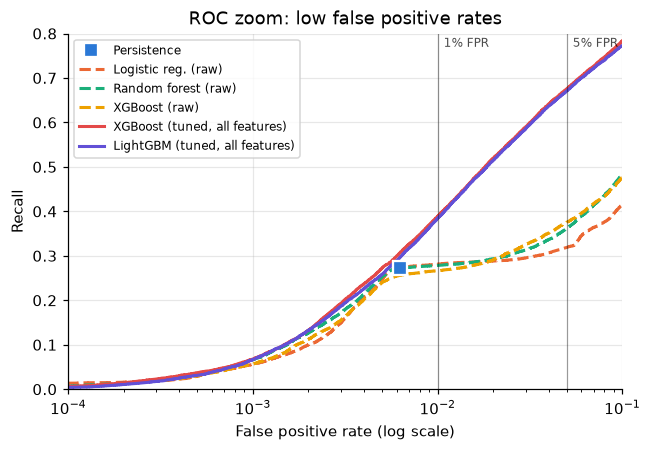

In [5]:
# The low-FPR end is where a fire agency would operate, so zoom in on FPR <= 10% (log x-axis).
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for m, label in MODELS.items():
    fpr, tpr, _ = roc_curve(y_flat, probs[m])
    if m == "persistence":  # single operating point (see PR plot); point 0 is the (0, 0) corner, point 1 is its real one
        ax.plot(fpr[1], tpr[1], "s", ms=9, color=COLORS[m], mec="white", mew=1.5, zorder=6, label=label)
        continue
    keep = fpr > 0  # log axis cannot show FPR = 0
    ax.plot(fpr[keep], tpr[keep], STYLE[m], color=COLORS[m], lw=2, label=label)
for x in (0.01, 0.05):  # the two fixed false positive rates reported in the results table
    ax.axvline(x, color="black", lw=0.8, alpha=0.4)
    ax.text(x * 1.08, 0.77, f"{x:.0%} FPR", fontsize=8, alpha=0.7)
ax.set(xscale="log", xlim=(1e-4, 0.1), ylim=(0, 0.8), xlabel="False positive rate (log scale)",
       ylabel="Recall", title="ROC zoom: low false positive rates")
ax.legend(fontsize=8, loc="upper left")
fig.savefig(FIGS / "eval_roc_lowfpr.png")
plt.show()

**Reading the curves**
- The two tuned models (solid) are clearly above every baseline across the whole PR curve:
  PR AUC 0.257 (XGBoost) and 0.248 (LightGBM) against 0.146-0.157 for models trained on the 12 raw channels.
  Engineered fire-neighbourhood features account for most of this gap (see Task 4).
- XGBoost and LightGBM are almost on top of each other, so the choice of boosting library matters far less than the features.
- Persistence is a single point (square; it outputs only 0 or 1): it finds 27% of next-day fire at 36% precision
  with a false positive rate of only 0.6%.
- The raw-channel baselines collapse right after recall ≈ 0.27: they rank pixels already burning on day t first
  ("fire stays where it is") and have almost no signal for new fire, so their precision drops to ~5%.
  Their eval-chosen operating points sit on top of persistence. The tuned models keep ≈0.25-0.45 precision up to recall 0.5,
  i.e. they also find *new* fire pixels near the front.
- Low-FPR zoom: at persistence's own false positive rate (0.62%) tuned XGBoost finds 31% of fire pixels vs 27%;
  at 1% / 5% FPR it finds 39% / 68%, while persistence stays at 27% (it has no other operating point).
- The eval-chosen threshold of the tuned models sits at higher recall (≈0.52) and lower precision (≈0.24) than the baselines,
  which is where their F1 is highest.
- ROC AUC is 0.80-0.91 for every learned model while PR AUC stays below 0.26. This is the class-imbalance effect explained above.

## 2 · Results table

Built from `reports/results.csv` and written to `reports/results_table.md`.
Precision, recall and F1 are at the threshold chosen on the **eval** split (not tuned on test).
Recall @ 1% / 5% FPR = share of fire pixels found when we allow 1% / 5% of no-fire pixels to be false alarms.

The paper rows are PR AUC from Huot et al. (2022) for reference only. They are not a like-for-like comparison:
their logistic regression and random forest also get the 8 neighbouring pixels of every channel as input,
and their numbers come from their own pipeline. The CNN is a convolutional autoencoder that sees the whole 64×64 patch.

In [6]:
COLUMNS = {  # results.csv column -> table header
    "pr_auc": "PR AUC", "roc_auc": "ROC AUC", "precision": "Precision", "recall": "Recall", "f1": "F1",
    "recall_at_1fpr": "Recall @ 1% FPR", "recall_at_5fpr": "Recall @ 5% FPR",
}
table = results.loc[list(MODELS), list(COLUMNS)].rename(columns=COLUMNS)   # pick rows/columns, rename headers
table.index = [MODELS[m] for m in table.index]     # file names -> readable model names
table.index.name = "Model"

# PR AUC reported by Huot et al. (2022); their LR / RF also use the 8 neighbouring pixels.
PAPER = {"Persistence": 0.115, "Logistic regression (+ 8 neighbours)": 0.198,
         "Random forest (+ 8 neighbours)": 0.225, "CNN autoencoder": 0.284}


def to_markdown(df, best_col_max=True):
    """Small markdown writer (avoids an extra dependency). Bold = best value in each column."""
    lines = ["| " + " | ".join([df.index.name] + list(df.columns)) + " |",    # header row
             "|" + "---|" + "---:|" * len(df.columns)]                        # separator; ---: = right-aligned numbers
    best = df.max() if best_col_max else None                                 # best (highest) value per column
    for name, row in df.iterrows():                                           # one markdown row per model
        cells = [f"**{v:.3f}**" if v == best[c] else f"{v:.3f}" for c, v in row.items()]
        lines.append("| " + " | ".join([name] + cells) + " |")
    return "\n".join(lines)                                                  # one string, rows separated by newlines


md_text = "\n".join([
    "# Phase 1 results (test split, 1,689 patches, 6.73M labelled pixels, 1.25% fire)",
    "",
    "Precision / recall / F1 at the decision threshold chosen on the eval split. Bold = best per column.",
    "",
    to_markdown(table),
    "",
    "## Reference: Huot et al. (2022), PR AUC on the same test split",
    "",
    "| Model | PR AUC |",
    "|---|---:|",
    *[f"| {k} | {v:.3f} |" for k, v in PAPER.items()],
    "",
    "Paper LR / RF also use the 8 neighbouring pixels of every channel; numbers are from their pipeline, "
    "so they are a reference point, not a like-for-like comparison.",
    "",
])
Path("reports/results_table.md").write_text(md_text)
print(md_text)

# Phase 1 results (test split, 1,689 patches, 6.73M labelled pixels, 1.25% fire)

Precision / recall / F1 at the decision threshold chosen on the eval split. Bold = best per column.

| Model | PR AUC | ROC AUC | Precision | Recall | F1 | Recall @ 1% FPR | Recall @ 5% FPR |
|---|---:|---:|---:|---:|---:|---:|---:|
| Persistence | 0.106 | 0.633 | 0.357 | 0.273 | 0.309 | 0.273 | 0.273 |
| Logistic reg. (raw) | 0.146 | 0.798 | **0.378** | 0.266 | 0.312 | 0.281 | 0.319 |
| Random forest (raw) | 0.157 | 0.816 | 0.371 | 0.270 | 0.312 | 0.279 | 0.362 |
| XGBoost (raw) | 0.145 | 0.795 | 0.337 | 0.257 | 0.292 | 0.267 | 0.375 |
| XGBoost (tuned, all features) | **0.257** | **0.906** | 0.242 | **0.526** | **0.332** | **0.388** | **0.675** |
| LightGBM (tuned, all features) | 0.248 | 0.903 | 0.242 | 0.520 | 0.331 | 0.384 | 0.671 |

## Reference: Huot et al. (2022), PR AUC on the same test split

| Model | PR AUC |
|---|---:|
| Persistence | 0.115 |
| Logistic regression (+ 8 neighbours) | 0.198 |
|

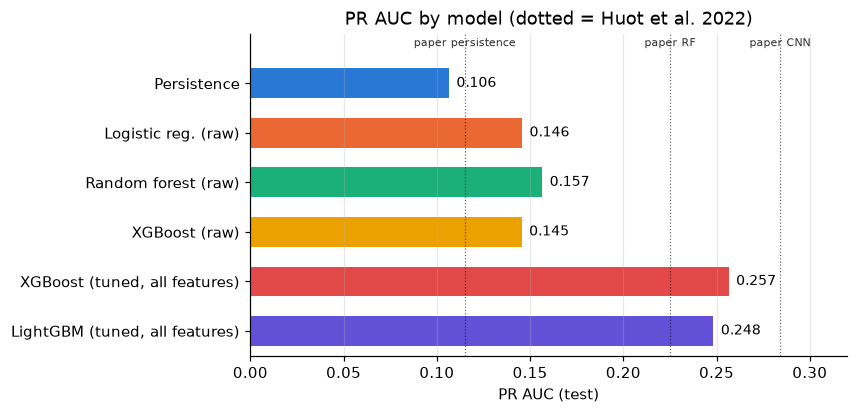

In [7]:
# Same table as a quick bar chart of the two threshold-free metrics plus the paper's PR AUC (for slides).
fig, ax = plt.subplots(figsize=(7, 3.8))
names = list(MODELS)
y = np.arange(len(names))                     # one bar position per model
ax.barh(y, results.loc[names, "pr_auc"], color=[COLORS[m] for m in names], height=0.6)
for i, m in enumerate(names):                 # write the value just right of each bar
    ax.text(results.loc[m, "pr_auc"] + 0.004, i, f"{results.loc[m, 'pr_auc']:.3f}", va="center", fontsize=9)
for v, lab in [(0.115, "paper persistence"), (0.225, "paper RF"), (0.284, "paper CNN")]:   # paper values as dotted lines
    ax.axvline(v, color="black", lw=0.8, ls=":", alpha=0.6)
    ax.text(v, -0.75, lab, fontsize=7.5, ha="center", alpha=0.8)
ax.set_yticks(y, [MODELS[m] for m in names])
ax.set_ylim(len(names) - 0.5, -1.0)  # top-to-bottom order, with room above the bars for the paper labels
ax.set(xlabel="PR AUC (test)", xlim=(0, 0.32), title="PR AUC by model (dotted = Huot et al. 2022)")
ax.grid(axis="y", visible=False)
fig.savefig(FIGS / "eval_pr_auc_bars.png")
plt.show()

**Reading the table**
- Tuned XGBoost is best on every threshold-free metric (PR AUC 0.257, ROC AUC 0.906, recall 39% @ 1% FPR, 68% @ 5% FPR).
  LightGBM is a close second (0.008 lower PR AUC).
- At the eval-chosen threshold the tuned models trade precision for recall: they find about 52-53% of next-day fire
  (vs 26-27% for the baselines) at 24% precision, giving the best F1 (0.33).
- The raw baselines do no better than persistence on F1 (0.29-0.31 vs 0.31) even though their PR AUC is higher:
  the extra ranking quality is all at recall levels persistence cannot reach.
- Against the paper: our persistence (0.106) is close to theirs (0.115). Our tuned XGBoost (0.257) is above their
  neighbour-feature random forest (0.225) but below their CNN (0.284): engineered features close most of the gap,
  and the remaining gap is the spatial context the Phase 2 CNN / U-Net is meant to capture.
- `best_f1` in results.csv (0.358 for XGBoost) is the F1 if the threshold were tuned on test; the gap to 0.332
  shows the eval-chosen threshold transfers well.

## 3 · Probability maps (tuned XGBoost, test patches)

Ten test patches are drawn at random (seed 0) from the patches that have at least one fire pixel on day t+1.
For each patch, four panels:
1. **Fire on day t** (`PrevFireMask`, a model input)
2. **True fire on day t+1** (`FireMask`, the label)
3. **XGBoost probability** of fire on day t+1; the arrow shows where the wind blows **to** (patch-mean wind)
4. **XGBoost thresholded** at the eval-chosen threshold, coloured by outcome:
   true positive, false positive (false alarm), false negative (missed fire)

Grey = label -1 (unknown, e.g. cloud). Patches are north-up, 64 × 64 km.

test patches: 1689, exact duplicates: 40
XGBoost eval-chosen threshold: 0.9152
1487 of 1689 test patches have next-day fire; chosen: [33, 69, 120, 290, 443, 515, 856, 1071, 1369, 1432]


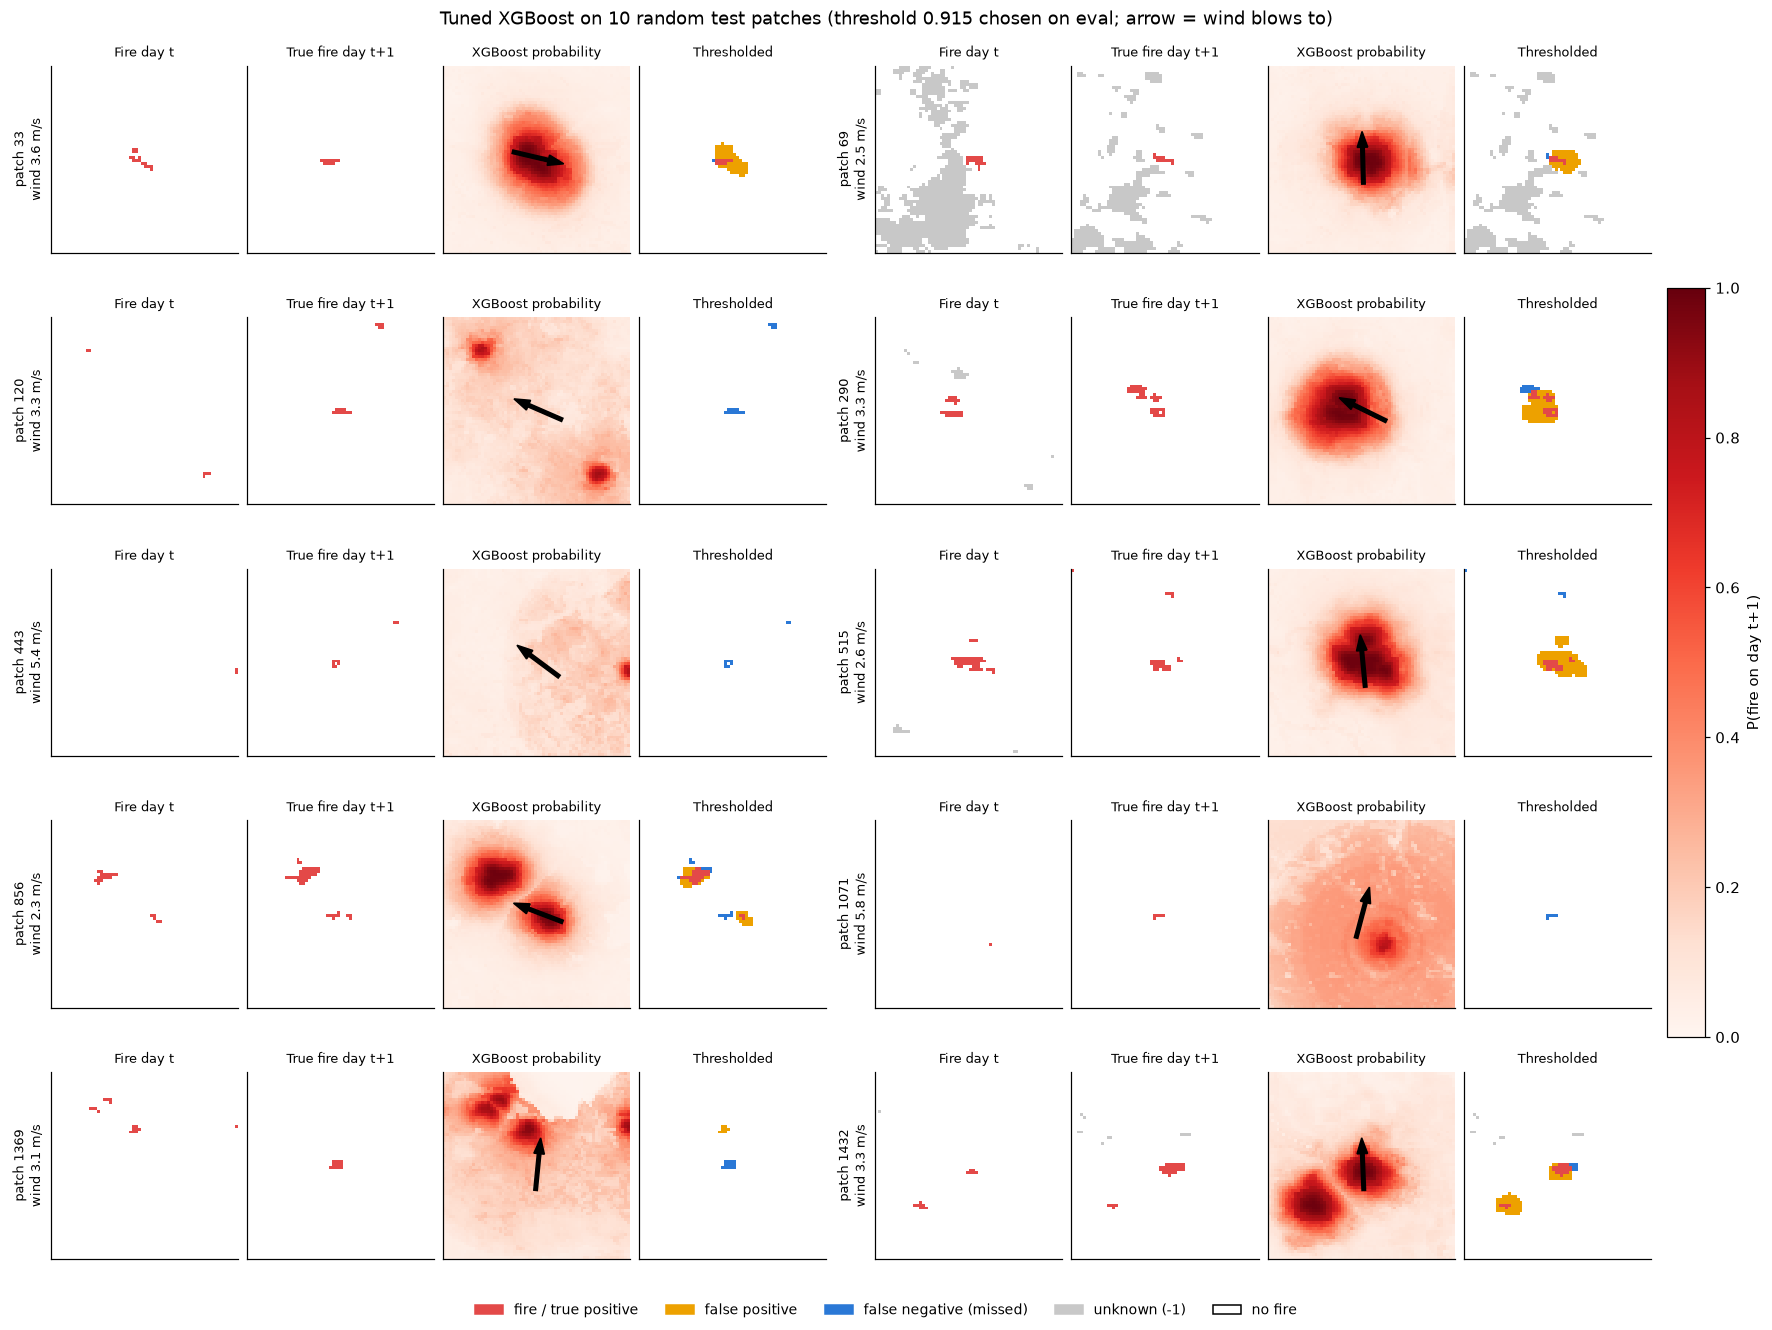

In [8]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from src.data import CHANNELS, load_split

# Day-t inputs we need for plotting: fire mask, wind direction and wind speed.
X_test, y_test = load_split("test")
assert (y_test == y_map).all(), "preds must be in load_split('test') order"
prev_map = X_test[:, CHANNELS.index("PrevFireMask")]
th_map = X_test[:, CHANNELS.index("th")] % 360   # wind comes FROM this direction, deg clockwise from north
vs_map = np.clip(X_test[:, CHANNELS.index("vs")], 0, None)   # wind speed, m/s
elev_map = X_test[:, CHANNELS.index("elevation")]             # used in Task 5 to spot crops of the same place
# The dataset has repeated patches; count exact copies (all 12 channels + label identical).
n_unique = len({X_test[i].tobytes() + y_test[i].tobytes() for i in range(len(X_test))})
print(f"test patches: {len(X_test)}, exact duplicates: {len(X_test) - n_unique}")
del X_test, y_test   # free ~350 MB

p_xgb = load_preds("xgboost")[1]               # (1689, 64, 64) probabilities
THR = results.loc["xgboost", "threshold"]      # chosen on eval
pred_xgb = p_xgb >= THR
print(f"XGBoost eval-chosen threshold: {THR:.4f}")

# Colours: grey unknown, white no fire, red fire. Outcome map: + TP red, FP orange, FN blue.
GREY, FIRE, FP_C, FN_C = "#c8c8c8", "#e34948", "#eda100", "#2a78d6"
MASK_CMAP = ListedColormap([GREY, "white", FIRE])               # values -1, 0, 1 shifted to 0, 1, 2
OUT_CMAP = ListedColormap([GREY, "white", FIRE, FP_C, FN_C])    # 0 unknown, 1 TN, 2 TP, 3 FP, 4 FN


def outcome_map(i):
    """Per-pixel outcome of the thresholded prediction for patch i (codes as in OUT_CMAP)."""
    y, p = y_map[i], pred_xgb[i]
    out = np.ones(y.shape, int)                 # true negative
    out[(y == 1) & p] = 2                       # true positive
    out[(y == 0) & p] = 3                       # false positive
    out[(y == 1) & ~p] = 4                      # false negative
    out[y == -1] = 0                            # unknown label
    return out


def wind_arrow(ax, i):
    """Arrow from the patch centre toward where the wind blows (opposite of th)."""
    th = np.deg2rad(th_map[i])                    # degrees -> radians for sin/cos
    # Circular mean: a plain mean of 350 and 10 degrees gives 180 (wrong); averaging sin and cos gives 0 (right).
    mean_th = np.arctan2(np.sin(th).mean(), np.cos(th).mean())
    # Wind FROM th blows TO th + 180. Patches are stored south-up (row index grows northward, see ROW_TO_NORTH in
    # src/features.py) and drawn with origin="lower", so x = column (east is +), y = row (north is +).
    # From north (th = 0) -> blows south -> dx = 0, dy = -1.  From east (th = 90) -> blows west -> dx = -1, dy = 0.
    dx, dy = -np.sin(mean_th), -np.cos(mean_th)
    # Arrow of length 18 px centred on the patch centre (32, 32).
    ax.arrow(32 - 9 * dx, 32 - 9 * dy, 18 * dx, 18 * dy, width=1.2, color="black", length_includes_head=True)


def plot_patches(idx, path, title):
    """Two patches per row, four panels per patch: day t | day t+1 | probability | thresholded."""
    n_rows = int(np.ceil(len(idx) / 2))          # 2 patches per row, e.g. 5 patches -> 3 rows
    fig, axes = plt.subplots(n_rows, 8, figsize=(16, 2.2 * n_rows + 1.0), squeeze=False, layout="constrained")
    heads = ["Fire day t", "True fire day t+1", "XGBoost probability", "Thresholded"]
    for k, ax in enumerate(axes.flat):           # maps need no axis ticks or grid
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if k // 4 >= len(idx):                   # hide empty panels when the number of patches is odd
            ax.axis("off")
    for n, i in enumerate(idx):
        a = axes[n // 2, 4 * (n % 2): 4 * (n % 2) + 4]   # the 4 panels of patch number n (left or right half of a row)
        # Masks hold -1/0/1; +1 shifts them to 0/1/2 = positions in MASK_CMAP (grey/white/red).
        a[0].imshow(prev_map[i] + 1, cmap=MASK_CMAP, vmin=0, vmax=2, interpolation="nearest", origin="lower")
        a[1].imshow(y_map[i] + 1, cmap=MASK_CMAP, vmin=0, vmax=2, interpolation="nearest", origin="lower")
        im = a[2].imshow(p_xgb[i], cmap="Reds", vmin=0, vmax=1, interpolation="nearest", origin="lower")
        wind_arrow(a[2], i)
        a[3].imshow(outcome_map(i), cmap=OUT_CMAP, vmin=0, vmax=4, interpolation="nearest", origin="lower")
        for h, ax in zip(heads, a):
            ax.set_title(h, fontsize=8.5)
        a[0].set_ylabel(f"patch {i}\nwind {vs_map[i].mean():.1f} m/s", fontsize=8.5)
    fig.suptitle(title, fontsize=12)
    handles = [Patch(color=FIRE, label="fire / true positive"), Patch(color=FP_C, label="false positive"),
               Patch(color=FN_C, label="false negative (missed)"), Patch(color=GREY, label="unknown (-1)"),
               Patch(facecolor="white", edgecolor="black", label="no fire")]
    fig.legend(handles=handles, loc="outside lower center", ncol=5, fontsize=9, frameon=False)
    fig.colorbar(im, ax=axes, shrink=0.6, pad=0.01, label="P(fire on day t+1)")
    fig.savefig(path)
    plt.show()


rng = np.random.default_rng(SEED)                               # seeded random generator -> same 10 patches every run
fire_patches = np.flatnonzero((y_map == 1).any(axis=(1, 2)))   # patches with next-day fire
chosen = np.sort(rng.choice(fire_patches, size=10, replace=False))   # 10 different patches, sorted for readability
print(f"{len(fire_patches)} of {len(y_map)} test patches have next-day fire; chosen: {chosen.tolist()}")
plot_patches(chosen, FIGS / "eval_prob_maps.png",
             f"Tuned XGBoost on 10 random test patches (threshold {THR:.3f} chosen on eval; arrow = wind blows to)")

In [9]:
# Per-patch numbers for the 10 maps above (pixels with label -1 excluded).
def patch_stats(idx):
    rows = []
    for i in idx:
        y, lab = y_map[i], y_map[i] != -1
        rows.append({
            "patch": i,
            "fire_t": int((prev_map[i] == 1).sum()),
            "fire_t+1": int((y == 1).sum()),
            "TP": int(((y == 1) & pred_xgb[i]).sum()),
            "FP": int(((y == 0) & pred_xgb[i]).sum()),
            "FN": int(((y == 1) & ~pred_xgb[i]).sum()),
            "unknown_t+1": int((~lab).sum()),
            "wind_m/s": round(float(vs_map[i].mean()), 1),
        })
    return pd.DataFrame(rows).set_index("patch")


patch_stats(chosen)

,fire_t,fire_t+1,TP,FP,FN,unknown_t+1,wind_m/s
patch,,,,,,,
33,16,11,10,69,1,0,3.6
69,19,12,10,57,2,443,2.5
120,6,16,0,0,16,0,3.3
290,23,43,28,83,15,0,3.3
443,2,9,0,0,9,0,5.4
515,48,29,24,114,5,0,2.6
856,22,47,31,44,16,0,2.3
1071,1,5,0,0,5,0,5.8
1369,17,13,0,8,13,0,3.1


**What the maps show**
- The probability map is a smooth halo around the day-t fire that fades over roughly 2-5 km.
  Its shape mostly follows the day-t fire mask, stretched slightly toward where the wind blows (patch 33 toward the
  east-south-east, patch 69 toward the north). This matches Task 4: distance to the nearest fire drives the model,
  and the upwind features add a smaller directional push.
- After thresholding, the prediction is close to "day-t fire grown by about 2 km": it catches fire that stays
  or creeps outward (patches 290, 856, 1432) and paints a false-positive ring around small fires that die down (33, 69, 515).
- Fire that appears away from the day-t fire is missed completely (120, 443, 1071, 1369): every next-day fire pixel in
  120, 443 and 1071 is a false negative.
- Patch 69 shows why -1 pixels must be masked: cloud hides much of the patch on day t and day t+1.
- The probabilities are **not calibrated**: training used a 1:5 subsampled table plus `scale_pos_weight` ≈ 5,
  which pushes every probability up; this is why the eval-chosen threshold is as high as 0.915.
  Only the ranking and the threshold matter for the metrics we report.

## 4 · Interpretability of tuned XGBoost

The model is refitted with exactly the stored hyperparameters (`best_params.json`, 216 trees) on the training pixel table,
then checked against the saved test predictions so we know we are explaining the same model.

In [10]:
import json
import shap
from xgboost import XGBClassifier
from src.features import ALL_FEATURES, FEATURE_GROUPS, load_pixels
from src.evaluate import metrics

params = json.loads(Path("reports/best_params.json").read_text())["xgboost"]   # tuned settings from src/train.py
print(params)

train = load_pixels("train")    # subsampled: all fire pixels + 5x no-fire, label -1 already dropped
model = XGBClassifier(**params) # same settings incl. random_state 0 -> same trees as the evaluated model
model.fit(train[ALL_FEATURES], train["label"])   # 35 feature columns in, 0/1 label out
del train                       # free memory

test = load_pixels("test")      # every test pixel, in patch/row/col order
# predict_proba gives [P(no fire), P(fire)] per pixel; keep column 1 and fold back into (patches, 64, 64) maps
p_refit = model.predict_proba(test[ALL_FEATURES])[:, 1].reshape(-1, 64, 64)
print(f"refit test PR AUC {metrics(y_map, p_refit)['pr_auc']:.4f} vs saved {results.loc['xgboost', 'pr_auc']:.4f}; "
      f"max |prob difference| vs saved preds = {np.abs(p_refit - p_xgb).max():.2e}")

{'colsample_bytree': 0.6326947454697227, 'gamma': 1, 'learning_rate': 0.025793638521878843, 'max_depth': 6, 'min_child_weight': 1, 'reg_lambda': 7.220917699605245, 'subsample': 0.7274275809805295, 'tree_method': 'hist', 'n_jobs': -1, 'random_state': 0, 'scale_pos_weight': 4.999538183420177, 'n_estimators': 216}


refit test PR AUC 0.2565 vs saved 0.2565; max |prob difference| vs saved preds = 0.00e+00


### 4a · Gain importance

XGBoost "gain" = average improvement in the training loss each time a feature is used for a split.
It says which features the trees rely on, but not in which direction they push the prediction (SHAP does that).
Bars are coloured by feature group.

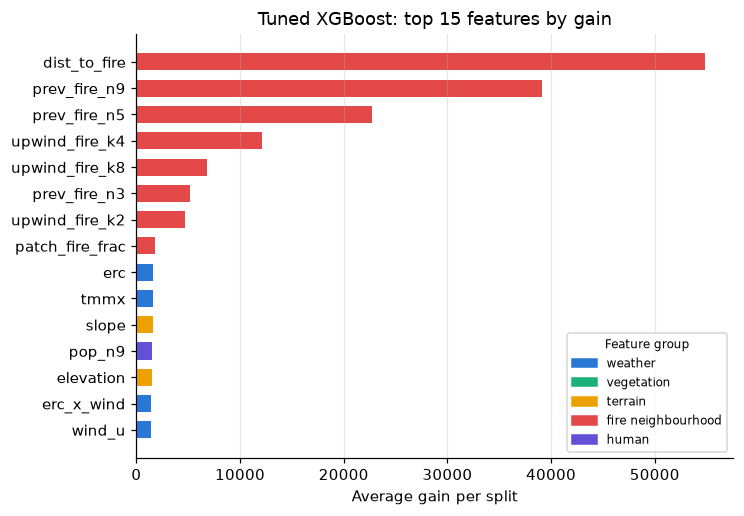

dist_to_fire       0.315
prev_fire_n9       0.225
prev_fire_n5       0.130
upwind_fire_k4     0.069
upwind_fire_k8     0.039
prev_fire_n3       0.030
upwind_fire_k2     0.027
patch_fire_frac    0.011
erc                0.009
tmmx               0.009
slope              0.009
pop_n9             0.009
elevation          0.009
erc_x_wind         0.008
wind_u             0.008
dtype: float64

In [11]:
GROUP_OF = {f: g for g, feats in FEATURE_GROUPS.items() for f in feats}   # feature name -> its group
GROUP_COLORS = dict(zip(FEATURE_GROUPS, ["#2a78d6", "#1baf7a", "#eda100", "#e34948", "#6250d6"]))

# get_score returns {feature: average gain}; sort from most to least important
gain = pd.Series(model.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
top = gain.head(15)

fig, ax = plt.subplots(figsize=(7, 5))
# [::-1] reverses the order so the most important feature is drawn at the top
ax.barh(top.index[::-1], top.values[::-1], color=[GROUP_COLORS[GROUP_OF[f]] for f in top.index[::-1]], height=0.65)
ax.set(xlabel="Average gain per split", title="Tuned XGBoost: top 15 features by gain")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=c, label=g.replace("_", " ")) for g, c in GROUP_COLORS.items()],
          loc="lower right", fontsize=8, title="Feature group", title_fontsize=8)
fig.savefig(FIGS / "eval_gain_importance.png")
plt.show()
(gain / gain.sum()).round(3).head(15)   # share of total gain per feature (sums to 1 over all features)

### 4b · SHAP values

SHAP splits each prediction (in log-odds) into one additive contribution per feature; positive = pushes toward fire.
`TreeExplainer` computes them exactly for tree models.
Sample: 20,000 labelled test pixels, 10,000 fire (drawn from the 84,331 fire pixels) and 10,000 no-fire, seed 0.
Fire pixels are over-represented on purpose so both classes are visible; the sample is for explaining, not for scoring.

(20000, 35) (20000, 35)


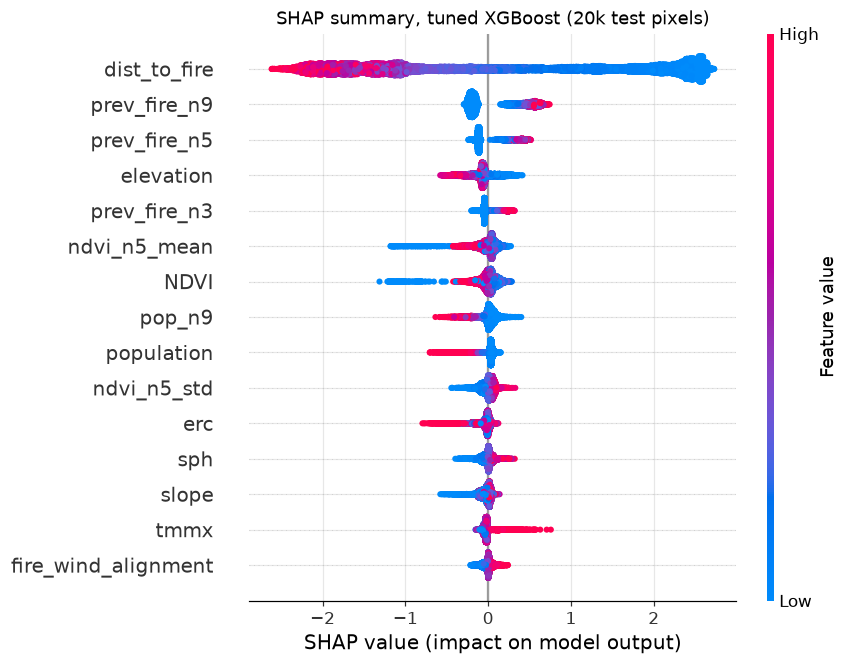

In [12]:
labelled_px = test[test["label"] != -1]               # drop unknown pixels
fire_px = labelled_px[labelled_px["label"] == 1]       # 84,331 fire pixels in test
n_fire = min(len(fire_px), 10_000)                     # keep all fire pixels, but at most 10k
sample = pd.concat([
    fire_px.sample(n_fire, random_state=SEED),                                     # 10k fire pixels
    labelled_px[labelled_px["label"] == 0].sample(20_000 - n_fire, random_state=SEED),   # fill up to 20k with no-fire
])
X_shap = sample[ALL_FEATURES]                          # only the 35 model inputs

explainer = shap.TreeExplainer(model)                  # exact SHAP for tree models
shap_values = explainer.shap_values(X_shap)     # (20000, n_features), log-odds units
print(X_shap.shape, shap_values.shape)

# One dot per pixel per feature: x = SHAP value (push toward / away from fire), colour = feature value (red = high).
shap.summary_plot(shap_values, X_shap, max_display=15, show=False, plot_size=(8, 6))
plt.title("SHAP summary, tuned XGBoost (20k test pixels)")
plt.savefig(FIGS / "eval_shap_summary.png")
plt.show()

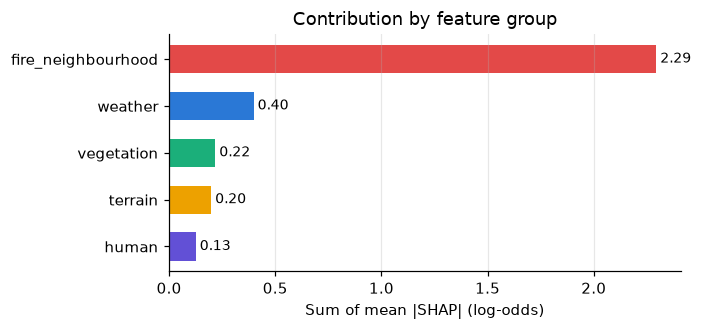

fire_neighbourhood    2.294
weather               0.398
vegetation            0.218
terrain               0.198
human                 0.126
dtype: float32

In [13]:
# Importance by feature group: sum of mean |SHAP| over the features in each group.
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=ALL_FEATURES)   # average size of each feature's push
by_group = mean_abs.groupby(GROUP_OF).sum().sort_values(ascending=False)      # add up the features of each group

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(by_group.index[::-1], by_group.values[::-1], color=[GROUP_COLORS[g] for g in by_group.index[::-1]], height=0.6)
for k, v in enumerate(by_group.values[::-1]):
    ax.text(v, k, f" {v:.2f}", va="center", fontsize=9)
ax.set(xlabel="Sum of mean |SHAP| (log-odds)", title="Contribution by feature group")
ax.grid(axis="y", visible=False)
fig.savefig(FIGS / "eval_shap_groups.png")
plt.show()
by_group.round(3)

### 4c · Physical plausibility check

Two questions:
1. **Does the model push risk downwind?** For every day-t fire pixel we step 1-5 pixels downwind (where the wind blows **to**)
   and 1-5 pixels upwind, keep the stepped-to pixels that are not burning on day t, and compare the mean predicted probability.
   The true next-day fire rate in the same pixels tells us whether the data itself shows downwind spread.
   Geometry: `th` is where the wind comes **from**, degrees clockwise from north; patches are stored south-up
   (row index grows northward, verified in `notebooks/notes_dataset.md`), so one pixel downwind is
   row − cos(th), column − sin(th).
2. **Do the SHAP signs make physical sense?** Spearman correlation between a feature's value and its SHAP value:
   positive = higher value pushes toward fire.

In [14]:
def wind_sides(prev, th, vs, labels, probs=None, wind_bins=(0, 99)):
    """Compare pixels 1-5 px downwind vs upwind of day-t fire.

    prev, th, vs, labels: (N, 64, 64) maps; probs: dict name -> (N, 64, 64) probabilities (optional).
    Only target pixels that are NOT burning on day t are used. One row per (wind band, distance, side).
    """
    fire = prev == 1
    pf, rf, cf = np.nonzero(fire)                          # patch, row, column of every day-t fire pixel
    rad = np.deg2rad(th[pf, rf, cf])                       # wind direction at each fire pixel, in radians
    step_row, step_col = -np.cos(rad), -np.sin(rad)         # one pixel downwind (rows grow northward), see wind_arrow
    speed = vs[pf, rf, cf]
    rows = []
    for lo, hi in zip(wind_bins[:-1], wind_bins[1:]):      # e.g. bins (0, 3, 5) -> bands 0-3 and 3-5 m/s
        m = (speed >= lo) & (speed < hi)                    # fire pixels in this wind-speed band
        for d in range(1, 6):                               # distances 1..5 pixels (= km)
            sides = {}
            for side, sign in (("downwind", 1), ("upwind", -1)):   # upwind = step the other way
                # walk d steps from each fire pixel and round to the nearest pixel
                r = np.rint(rf[m] + sign * d * step_row[m]).astype(int)
                c = np.rint(cf[m] + sign * d * step_col[m]).astype(int)
                inside = (r >= 0) & (r < 64) & (c >= 0) & (c < 64)  # drop steps that leave the patch
                # turn (patch, row, col) into one number per pixel so duplicates can be removed with np.unique
                flat = np.unique(np.ravel_multi_index((pf[m][inside], r[inside], c[inside]), labels.shape))
                sides[side] = flat[~fire.flat[flat]]        # drop pixels already burning on day t
            both = np.intersect1d(sides["downwind"], sides["upwind"])  # downwind of one fire, upwind of another
            for side, idx in sides.items():
                idx = np.setdiff1d(idx, both)               # such pixels are ambiguous, so remove them from both sides
                y = labels.flat[idx]                        # their true next-day labels
                row = {"wind_m/s": f"{lo}-{hi}", "distance_px": d, "side": side, "pixels": len(idx),
                       "true_fire_rate": (y[y != -1] == 1).mean()}   # share that really burns on day t+1
                for name, p in (probs or {}).items():
                    row[name] = p.flat[idx].mean()          # mean predicted probability in the same pixels
                rows.append(row)
    return pd.DataFrame(rows)


p_raw = load_preds("xgb_raw")[1]     # raw-channel XGBoost, for comparison (it has no fire-distance features)
wind_check =wind_sides(prev_map, th_map, vs_map, y_map, {"xgb_tuned": p_xgb, "xgb_raw": p_raw})
wind_check.round(3)

,wind_m/s,distance_px,side,pixels,true_fire_rate,xgb_tuned,xgb_raw
0,0-99,1,downwind,20657,0.189,0.939,0.435
1,0-99,1,upwind,20749,0.216,0.936,0.430
2,0-99,2,downwind,30848,0.156,0.923,0.438
3,0-99,2,upwind,31102,0.180,0.917,0.431
4,0-99,3,downwind,37369,0.131,0.902,0.439
5,0-99,3,upwind,37790,0.153,0.889,0.433
6,0-99,4,downwind,41668,0.112,0.876,0.440
7,0-99,4,upwind,41963,0.131,0.856,0.434
8,0-99,5,downwind,44392,0.098,0.849,0.437
9,0-99,5,upwind,44821,0.117,0.820,0.435


In [15]:
# Does the DATA show downwind spread? Same check on the much larger train split, split by wind speed
# (wind direction only matters when there is wind). Only the 3 channels we need are kept in memory.
X_tr, y_tr = load_split("train")
prev_tr, th_tr = X_tr[:, CHANNELS.index("PrevFireMask")], X_tr[:, CHANNELS.index("th")] % 360
vs_tr = np.clip(X_tr[:, CHANNELS.index("vs")], 0, None)
del X_tr
BANDS = (0, 3, 5, 8, 99)             # wind-speed bands in m/s: 0-3, 3-5, 5-8, 8+
by_wind = pd.concat([                # one table with a "split" column saying train or test
    wind_sides(prev_tr, th_tr, vs_tr, y_tr, wind_bins=BANDS).assign(split="train"),
    wind_sides(prev_map, th_map, vs_map, y_map, wind_bins=BANDS).assign(split="test"),
])
del prev_tr, th_tr, vs_tr, y_tr
# Ratio > 1: more next-day fire downwind than upwind (what physics predicts).
# pivot_table puts downwind and upwind side by side in one row per (split, wind band, distance)
ratio = by_wind.pivot_table(index=["split", "wind_m/s", "distance_px"], columns="side", values="true_fire_rate")
ratio["down/up"] = ratio["downwind"] / ratio["upwind"]
ratio.loc[(slice(None), slice(None), [2, 5]), :].round(3)   # show only distances 2 and 5 km to keep it short

side                        downwind  upwind  down/up
split wind_m/s distance_px                           
test  0-3      2               0.161   0.160    1.005
               5               0.102   0.094    1.081
      3-5      2               0.158   0.191    0.828
               5               0.102   0.130    0.782
      5-8      2               0.114   0.186    0.614
               5               0.044   0.100    0.444
      8-99     2               0.000   0.000      NaN
               5               0.000   0.000      NaN
train 0-3      2               0.195   0.186    1.048
               5               0.124   0.109    1.135
      3-5      2               0.192   0.176    1.089
               5               0.130   0.104    1.250
      5-8      2               0.197   0.169    1.160
               5               0.148   0.102    1.457
      8-99     2               0.109   0.087    1.254
               5               0.118   0.038    3.100

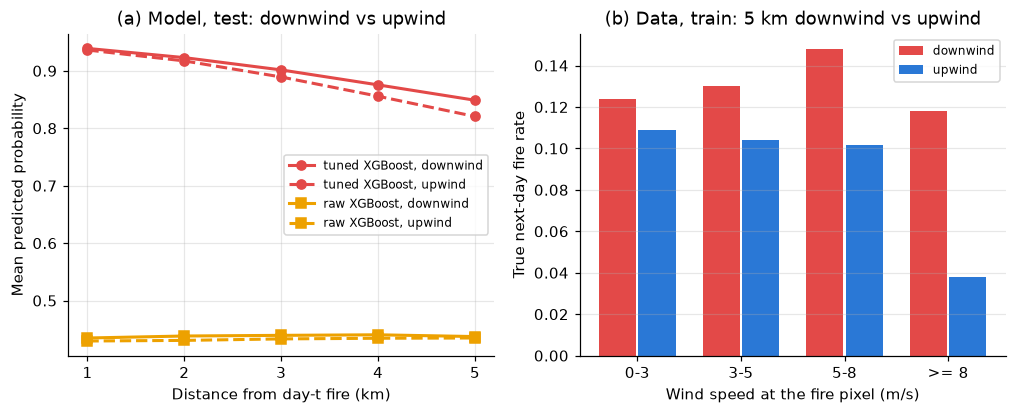

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
# (a) model: mean probability downwind vs upwind, all wind speeds, test split
for name, color, mk in (("xgb_tuned", "#e34948", "o"), ("xgb_raw", "#eda100", "s")):
    for side, ls in (("downwind", "-"), ("upwind", "--")):
        s = wind_check[wind_check["side"] == side]
        axes[0].plot(s["distance_px"], s[name], ls, marker=mk, lw=2, color=color,
                     label=f"{'tuned' if name == 'xgb_tuned' else 'raw'} XGBoost, {side}")
axes[0].set(xlabel="Distance from day-t fire (km)", ylabel="Mean predicted probability", xticks=range(1, 6),
            title="(a) Model, test: downwind vs upwind")
axes[0].legend(fontsize=8)
# (b) data: true fire rate 5 km downwind vs upwind, by wind speed, train split
s = by_wind[(by_wind["split"] == "train") & (by_wind["distance_px"] == 5)]
x = np.arange(len(BANDS) - 1)                 # one group of 2 bars per wind band
for k, (side, color) in enumerate((("downwind", "#e34948"), ("upwind", "#2a78d6"))):
    v = s[s["side"] == side]["true_fire_rate"].to_numpy()
    # k = 0 -> bar shifted left, k = 1 -> shifted right, so the two sides sit next to each other
    axes[1].bar(x + (k - 0.5) * 0.38, v, width=0.36, color=color, label=side)
axes[1].set_xticks(x, [f"{a}-{b}" if b < 99 else f">= {a}" for a, b in zip(BANDS[:-1], BANDS[1:])])
axes[1].set(xlabel="Wind speed at the fire pixel (m/s)", ylabel="True next-day fire rate",
            title="(b) Data, train: 5 km downwind vs upwind")
axes[1].grid(axis="x", visible=False)
axes[1].legend(fontsize=8)
fig.savefig(FIGS / "eval_downwind_check.png")
plt.show()

In [17]:
CHECK = ["upwind_fire_k2", "upwind_fire_k4", "upwind_fire_k8", "fire_wind_alignment",
         "dist_to_fire", "prev_fire_n3", "min_rel_humidity", "vpd", "erc", "vs", "NDVI", "slope"]
# Spearman = correlation of ranks: +1 means "higher feature value -> always higher SHAP (more fire)", -1 the opposite.
# The SHAP column is wrapped in a Series with the same index as X_shap so pandas can pair the rows.
sign_table = pd.DataFrame({
    "mean_abs_shap": mean_abs[CHECK],
    "spearman(value, shap)": [X_shap[f].corr(pd.Series(shap_values[:, ALL_FEATURES.index(f)], index=X_shap.index),
                                             method="spearman") for f in CHECK],
})
sign_table.round(3)

,mean_abs_shap,"spearman(value, shap)"
upwind_fire_k2,0.010,0.685
upwind_fire_k4,0.011,0.606
upwind_fire_k8,0.015,0.491
fire_wind_alignment,0.043,0.913
dist_to_fire,1.583,-0.970
prev_fire_n3,0.083,0.752
min_rel_humidity,0.017,-0.642
vpd,0.038,0.720
erc,0.051,-0.129
vs,0.026,0.720


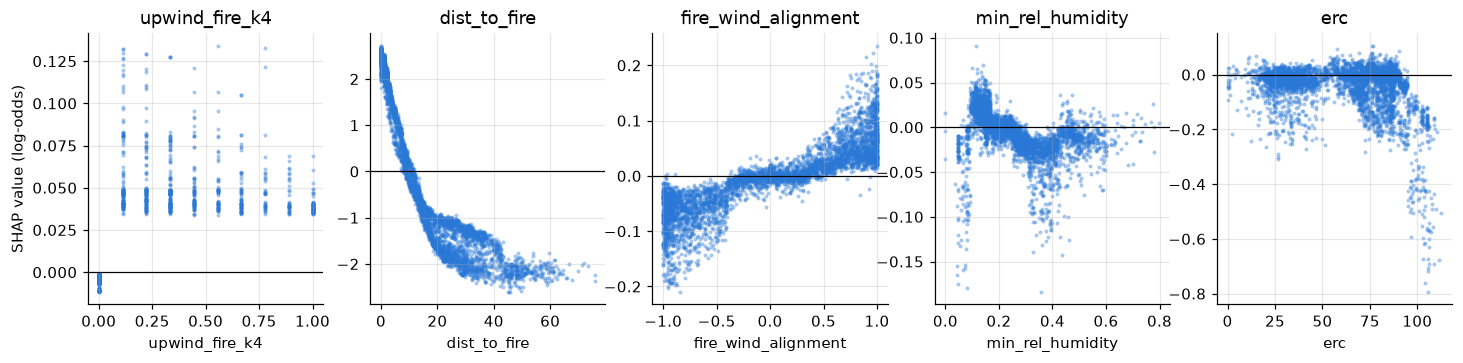

In [18]:
# Dependence plots: how the SHAP value of a feature changes with its value (5k points per panel).
show = ["upwind_fire_k4", "dist_to_fire", "fire_wind_alignment", "min_rel_humidity", "erc"]
pts = np.random.default_rng(SEED).choice(len(X_shap), 5000, replace=False)   # 5k of the 20k rows, so dots stay readable
fig, axes = plt.subplots(1, len(show), figsize=(16, 3.2))
for ax, f in zip(axes, show):
    # x = feature value, y = its SHAP value; above 0 = pushes toward fire
    ax.scatter(X_shap[f].to_numpy()[pts], shap_values[pts, ALL_FEATURES.index(f)], s=3, alpha=0.3, color="#2a78d6")
    ax.axhline(0, color="black", lw=0.8)
    ax.set(xlabel=f, title=f)
axes[0].set_ylabel("SHAP value (log-odds)")
fig.savefig(FIGS / "eval_shap_dependence.png")
plt.show()

**Interpretation**

*What the model relies on.* The refitted model is identical to the evaluated one (same test PR AUC, zero difference in
probabilities). The 8 fire-neighbourhood features in the gain top 15 hold ≈85% of total gain:
`dist_to_fire` 32%, `prev_fire_n9` 23%, `prev_fire_n5` 13%, and the three upwind features 13.5% together
(`upwind_fire_k4` 6.9%, `k8` 3.9%, `k2` 2.7%). SHAP agrees: the fire-neighbourhood group contributes
2.29 log-odds on average against 0.40 for all weather features together (≈71% of the total).
`dist_to_fire` alone moves a prediction from about +2.5 (at the fire) to −2.5 (40+ km away), crossing zero near 10 km.

*Signs that agree with fire physics.*
- Closer to fire and more fire nearby → higher risk (`dist_to_fire` ρ = −0.97, `prev_fire_n3` +0.75).
- Low NDVI (bare ground, water, no fuel) → strongly lower risk (ρ = −0.82); flat terrain (low slope) → lower risk (+0.44).
- Drier air → higher risk: `vpd` + (ρ = +0.72), `min_rel_humidity` − (ρ = −0.64).
- Higher wind speed → higher risk (`vs` ρ = +0.72).
- Fire 2/4/8 px upwind raises the prediction (ρ = +0.69 / +0.61 / +0.49), and `fire_wind_alignment` now has a clear
  positive effect (ρ = +0.91, mean |SHAP| 0.043): a pixel downwind of the nearest fire gets a higher prediction.
  These effects are still small next to `dist_to_fire` (mean |SHAP| 1.58).

*Signs that do not.* High `erc` (dry fuel) lowers risk, almost only above ≈95 (SHAP down to −0.8 there; ρ = −0.13 overall). ERC is a regional value (4 km grid,
almost constant over a patch), so the model most likely uses it as a proxy for *where/when* a fire is, not as a
causal driver. `vpd` and `min_rel_humidity` carry the physically correct dryness effect.

*Does the model push risk downwind?* **Yes, a little.** In panel (a) the mean probability downwind of day-t fire is
above the upwind value at every distance, and the gap grows with distance (0.003 at 1 km, 0.029 at 5 km).
The raw-channel XGBoost is flat at ≈0.43 because it does not know where the fire is.

*Does the data show downwind spread?* **Yes, on the train split** (panel b): 5 km from the fire, next-day fire is
1.14× more frequent downwind than upwind in calm wind (0-3 m/s), 1.25× at 3-5 m/s, 1.46× at 5-8 m/s and 3.1× at
8 m/s or more. The effect grows with wind speed, as fire physics predicts.

*Note on orientation.* A first version of this check assumed north-up patches and found the opposite in strong wind.
That led to verifying the orientation from the data (`notebooks/notes_dataset.md`): the arrays are stored south-up.
With the corrected geometry the train split shows clean downwind spread, and the upwind features' share of gain
rose from 9.4% to 13.5%.

*Test split caveat.* On test the downwind excess holds in calm wind (1.08× at 5 km) but not at 3-8 m/s (0.78×, 0.44×),
and there are no labelled pixels at 8+ m/s. The test split is only 257 fire events, and the 10 largest hold 57% of the
next-day fire pixels (Section 6), so these test ratios reflect a handful of fires. The train split (14,979 patches)
is the reliable estimate.

*For Phase 2.* The hand-coded wind features carry real but modest signal; a CNN sees the wind field and the fire front
together as images and can learn their interaction directly.

## 5 · Error analysis (tuned XGBoost at the eval-chosen threshold)

For each test patch, count false-positive pixels (predicted fire, no fire on day t+1) and false-negative pixels
(fire on day t+1, not predicted); -1 pixels are ignored. The 5 worst patches of each kind are plotted as in Task 3.

test totals: TP 44,409  FP 138,714  FN 39,922


worst FP patches: [285, 475, 1339, 368, 656] | worst FN patches: [173, 1264, 513, 1199, 106]
share of all FP in the 5 worst patches: 0.029
share of all FN in the 5 worst patches: 0.038


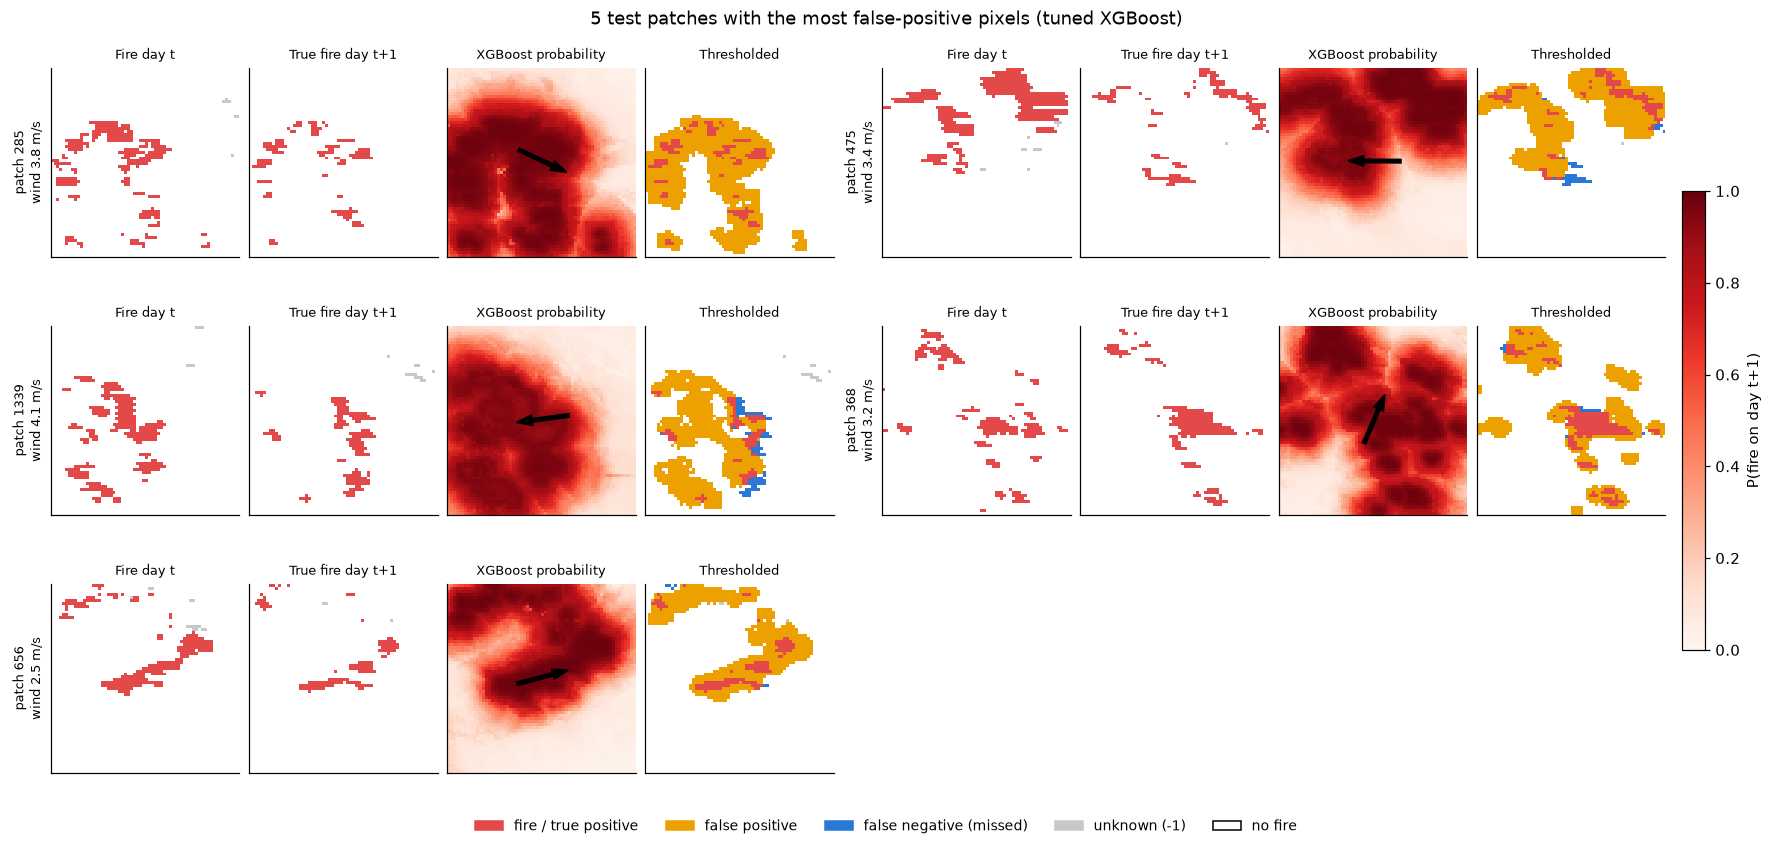

,fire_t,fire_t+1,TP,FP,FN,unknown_t+1,wind_m/s
patch,,,,,,,
285,316,162,162,1002,0,0,3.8
475,468,193,152,855,41,1,3.4
1339,334,189,109,816,80,13,4.1
368,277,259,245,675,14,0,3.2
656,255,136,130,673,6,3,2.5


In [19]:
# Count pixels of each outcome per patch; sum(axis=(1, 2)) adds up over rows and columns -> one number per patch.
# Labels -1 are neither 0 nor 1, so they never count.
tp = ((y_map == 1) & pred_xgb).sum(axis=(1, 2))     # fire, predicted fire
fp = ((y_map == 0) & pred_xgb).sum(axis=(1, 2))     # no fire, predicted fire (false alarm)
fn = ((y_map == 1) & ~pred_xgb).sum(axis=(1, 2))    # fire, not predicted (missed)
print(f"test totals: TP {tp.sum():,}  FP {fp.sum():,}  FN {fn.sum():,}")

fire_t_px = (prev_map == 1).sum(axis=(1, 2))        # burning pixels on day t, per patch
fire_t1_px = (y_map == 1).sum(axis=(1, 2))          # burning pixels on day t+1, per patch


from numpy.lib.stride_tricks import sliding_window_view


def same_place(a, b, k=16):
    """True if any of 9 k x k elevation blocks of patch a appears exactly (shifted) inside patch b.

    Elevation is static, so two crops of the same place share it, just shifted. Checking 9 blocks spread over
    the patch catches crops that overlap only partly. A flat block (e.g. sea) is skipped: it could match anywhere.
    """
    windows = sliding_window_view(elev_map[b], (k, k))       # every k x k window of patch b: shape (49, 49, k, k)
    for r0 in (0, 24, 48):                                   # 3 x 3 block positions: corners, edges and centre
        for c0 in (0, 24, 48):
            block = elev_map[a, r0:r0 + k, c0:c0 + k]
            # (windows == block) compares the block with every window; .all over the k x k pixels -> exact match,
            # .any over all windows -> the block appears somewhere in b
            if block.std() > 0 and (windows == block).all(axis=(2, 3)).any():
                return True
    return False


def distinct_fires(order, k=5):
    """First k patches in `order` that show different places (so different fires).

    The dataset contains several overlapping crops of the same large fire; without this check the
    5 worst false-negative patches were 5 crops of one fire.
    """
    keep = []
    for i in order:                                          # go down the list, worst patch first
        # keep i only if it is a different place from every patch kept so far (check both directions)
        if not any(same_place(i, j) or same_place(j, i) for j in keep):
            keep.append(i)
        if len(keep) == k:
            break
    return np.array(keep)


# argsort(-fp) = patch indices from most to fewest false positives ("stable" keeps ties in index order)
worst_fp = distinct_fires(np.argsort(-fp, kind="stable"))
worst_fn = distinct_fires(np.argsort(-fn, kind="stable"))
print("worst FP patches:", worst_fp.tolist(), "| worst FN patches:", worst_fn.tolist())
print("share of all FP in the 5 worst patches:", round(fp[worst_fp].sum() / fp.sum(), 3))
print("share of all FN in the 5 worst patches:", round(fn[worst_fn].sum() / fn.sum(), 3))

plot_patches(worst_fp, FIGS / "eval_worst_fp.png", "5 test patches with the most false-positive pixels (tuned XGBoost)")
patch_stats(worst_fp)

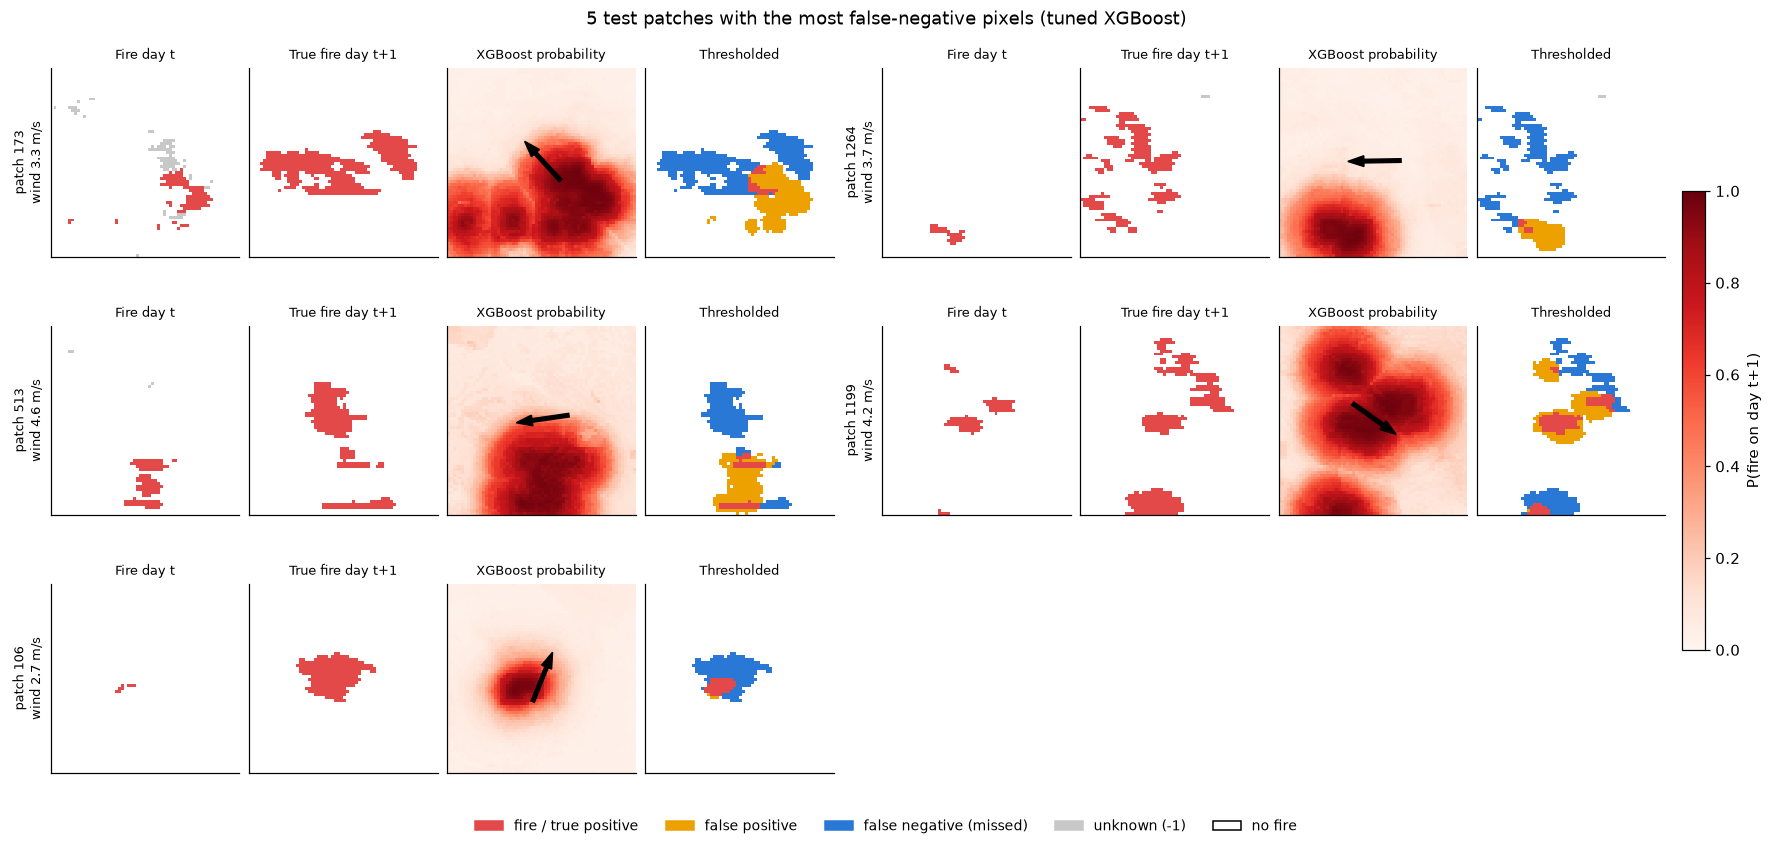

,fire_t,fire_t+1,TP,FP,FN,unknown_t+1,wind_m/s
patch,,,,,,,
173,116,515,35,302,480,0,3.3
1264,35,333,13,117,320,3,3.7
513,121,324,60,212,264,0,4.6
1199,104,406,145,217,261,0,4.2
106,8,260,50,4,210,0,2.7


In [20]:
plot_patches(worst_fn, FIGS / "eval_worst_fn.png", "5 test patches with the most false-negative pixels (tuned XGBoost)")
patch_stats(worst_fn)

In [21]:
# Split-wide patterns behind the worst cases.
dist = test["dist_to_fire"].to_numpy().reshape(-1, 64, 64)   # km to nearest day-t fire (90.5 = no fire in patch)
fn_px, fp_px = (y_map == 1) & ~pred_xgb, (y_map == 0) & pred_xgb
no_fire_t = ~(prev_map == 1).any(axis=(1, 2))                  # patches with no day-t fire at all
shrinking = fire_t1_px < fire_t_px                            # fire covers fewer pixels on day t+1

# .mean() of a True/False array = share of True. np.nonzero(fp_px)[0] = patch index of every FP pixel.
summary = pd.Series({
    "FN pixels > 5 km from any day-t fire": (dist[fn_px] > 5).mean(),
    "test patches with no day-t fire (count)": no_fire_t.sum(),
    "TP pixels > 5 km from any day-t fire": (dist[(y_map == 1) & pred_xgb] > 5).mean(),
    "FP pixels within 2 km of day-t fire": (dist[fp_px] <= 2).mean(),
    "FP pixels in shrinking-fire patches": shrinking[np.nonzero(fp_px)[0]].mean(),
    "patches that are shrinking (of patches with day-t fire)": shrinking[~no_fire_t].mean(),
    "day-t fire pixels still burning on day t+1": (y_map[prev_map == 1] == 1).mean(),
})
summary.round(3)

FN pixels > 5 km from any day-t fire                       0.644
test patches with no day-t fire (count)                    0.000
TP pixels > 5 km from any day-t fire                       0.000
FP pixels within 2 km of day-t fire                        0.888
FP pixels in shrinking-fire patches                        0.531
patches that are shrinking (of patches with day-t fire)    0.384
day-t fire pixels still burning on day t+1                 0.353
dtype: float64

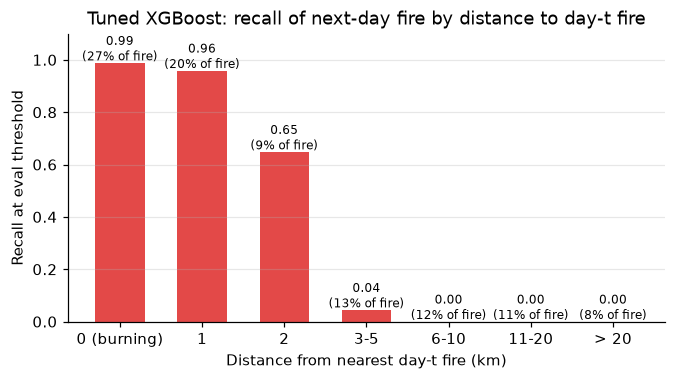

,fire pixels,share of all fire,recall
band,,,
0 (burning),23003,0.273,0.988
1,16916,0.201,0.959
2,7675,0.091,0.648
3-5,11024,0.131,0.044
6-10,10041,0.119,0.000
11-20,8968,0.106,0.000
> 20,6704,0.079,0.000


In [22]:
# Recall by distance to the nearest day-t fire: how fast does the model's skill fall off away from the front?
bins = [0, 0.5, 1.5, 2.5, 5, 10, 20, 91]     # km edges; 0-0.5 = the pixel itself is burning on day t
names = ["0 (burning)", "1", "2", "3-5", "6-10", "11-20", "> 20"]
fire_px_mask = y_map == 1                    # recall is about next-day fire pixels only
band = pd.cut(dist[fire_px_mask], bins, labels=names, include_lowest=True)   # distance band of every fire pixel
# group fire pixels by band; "found" is True when the model predicted fire there
by_dist = pd.DataFrame({"band": band, "found": pred_xgb[fire_px_mask]}).groupby("band", observed=False)["found"]
recall_by_dist = pd.DataFrame({"fire pixels": by_dist.size(), "share of all fire": by_dist.size() / fire_px_mask.sum(),
                               "recall": by_dist.mean()})   # mean of True/False = share found = recall

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(recall_by_dist.index.astype(str), recall_by_dist["recall"], color="#e34948", width=0.6)
for k, (r, s) in enumerate(zip(recall_by_dist["recall"], recall_by_dist["share of all fire"])):
    ax.text(k, r + 0.01, f"{r:.2f}\n({s:.0%} of fire)", ha="center", fontsize=8)
ax.set(xlabel="Distance from nearest day-t fire (km)", ylabel="Recall at eval threshold", ylim=(0, 1.1),
       title="Tuned XGBoost: recall of next-day fire by distance to day-t fire")
ax.grid(axis="x", visible=False)
fig.savefig(FIGS / "eval_recall_by_distance.png")
plt.show()
recall_by_dist.round(3)

**Error patterns**

Totals at the eval threshold: 44.4k true positives, 138.7k false positives and 39.9k false negatives
(precision 0.24, recall 0.53).

*False positives: the model over-predicts around large, fragmented fires that are dying down.*
The 5 worst patches (285, 475, 1339, 368, 656) all hold large, scattered day-t fires (255-468 pixels), and the model draws a
≈2 km halo of high probability around every burning pixel. In 4 of the 5 the fire shrinks the next day
(316→162, 468→193, 334→189, 255→136 pixels). Split-wide, only 35% of day-t fire pixels still burn on day t+1;
89% of all false positives lie within 2 km of day-t fire, and 53% come from shrinking patches although only 38% of patches shrink.
The features cannot say which fires will die down: there is no burn-scar (fuel already consumed), containment or
next-day weather information. Detection noise in MODIS (smoke, satellite timing) adds to it.

*False negatives: the model misses long jumps and explosive growth.*
- Long-range spread or new fire 10-40 km from the day-t fire: patch 173 (the fire runs ≈30 km west),
  1264 and 513 (new fire 15-40 km north of the day-t fire), 1199 (new clusters to the north-east).
  In 173 part of the day-t fire is hidden under cloud (grey), so the true front was partly invisible to the model.
- Explosive growth of a small fire: patch 106 goes from 8 to 260 burning pixels; the predicted halo covers only the centre.
- Split-wide, 64% of missed fire pixels are more than 5 km from any day-t fire, and the model finds **no** fire pixel
  beyond 5 km. 43% of next-day fire lies 3 km or more from the day-t fire, and recall there is about 1%
  (99% on already-burning pixels, 96% at 1 km, 65% at 2 km, 4% at 3-5 km).

*Data caveat.* The test split holds 40 exact duplicate patches and several overlapping crops of the same large fire
(the first version of this analysis picked 5 crops of one fire as the "5 worst"). Pixel metrics are therefore weighted
toward large fires; Section 6 scores every fire event separately to check this.

*What this means for Phase 2.* A per-pixel model with neighbourhood summaries learns a fixed-radius halo.
The errors are about fire-front shape, long-range spread and whether a fire is growing or dying,
which is spatial context a CNN / U-Net sees directly.

## 6 · Event-level evaluation

The project brief asks to **evaluate by fire event**. Every metric above pools all test pixels together, so a large fire
that appears in many patches (several days, overlapping crops, exact duplicates) is counted many times and dominates.
Here the test patches are grouped into **events** and every event is scored on its own; the average over events gives
each fire the same weight, small or large.

**How patches are grouped.** The dataset has no fire ID or date, so we reuse the idea from Task 5: elevation never changes,
so two crops of the same place contain identical elevation values, only shifted. Two patches are *linked* if one of the
9 elevation blocks (16 × 16 px) of one patch appears exactly somewhere inside the other. Links are then chained
(A linked to B and B linked to C → A, B, C are one event).

**Limitation.** An event here means "one place". Two different fires at the same place (e.g. in different years) are merged,
and two crops of one fire that do not overlap stay separate.

In [23]:
K = 16                     # block size in pixels (same as same_place() in Task 5)
STARTS = (0, 24, 48)       # 3 x 3 = 9 block positions spread over the 64 x 64 patch
n_patches = len(elev_map)

# Step 1: store the 9 elevation blocks of every patch.
# Key = the block's raw bytes (so only exactly equal blocks match), value = set of patches that own this block.
blocks = {}
for a in range(n_patches):
    for r0 in STARTS:
        for c0 in STARTS:
            block = elev_map[a, r0:r0 + K, c0:c0 + K]
            if block.std() > 0:               # a flat block (e.g. sea) could match anywhere, so skip it
                blocks.setdefault(block.tobytes(), set()).add(a)

# Step 2: slide a K x K window over every patch b. If a window equals a stored block of patch a,
# then a and b are crops of the same place -> link them (in both directions).
links = {i: set() for i in range(n_patches)}
for b in range(n_patches):
    windows = sliding_window_view(elev_map[b], (K, K)).reshape(-1, K, K)   # all 49 x 49 windows of patch b
    for w in windows:
        for a in blocks.get(w.tobytes(), ()):    # patches whose block equals this window (usually none)
            if a != b:
                links[a].add(b)
                links[b].add(a)

# Step 3: chain the links into groups (connected components) with a simple depth-first search.
event_of = np.full(n_patches, -1)        # event id of every patch; -1 = not assigned yet
for start in range(n_patches):
    if event_of[start] != -1:            # already part of an earlier group
        continue
    event_of[start] = start              # event id = first patch of the group
    stack = [start]
    while stack:                         # visit every patch reachable through links
        i = stack.pop()
        for j in links[i]:
            if event_of[j] == -1:
                event_of[j] = start
                stack.append(j)

size = pd.Series(event_of).value_counts()                         # patches per event, largest first
fire_per_event = pd.Series((y_map == 1).sum(axis=(1, 2))).groupby(event_of).sum()   # next-day fire pixels per event
top10 = size.index[:10]                                           # the 10 events with the most patches
print(f"{n_patches} test patches -> {len(size)} events; {(size == 1).sum()} events are a single patch")
print(f"largest events (patches): {size.head(5).tolist()}")
print(f"the 10 largest events hold {size.head(10).sum() / n_patches:.0%} of test patches "
      f"and {fire_per_event[top10].sum() / fire_per_event.sum():.0%} of next-day fire pixels")

1689 test patches -> 257 events; 87 events are a single patch
largest events (patches): [127, 99, 91, 68, 62]
the 10 largest events hold 39% of test patches and 57% of next-day fire pixels


In [24]:
from sklearn.metrics import average_precision_score


def event_scores(name):
    """PR AUC and recall (at the eval-chosen threshold) of one model, computed separately for every event."""
    p_map = load_preds(name)[1]
    thr = results.loc[name, "threshold"]
    rows = []
    for e in size.index:
        in_event = event_of == e                  # patches of this event
        y = y_map[in_event].ravel()               # all their pixels as one vector
        p = p_map[in_event].ravel()
        keep = y != -1                            # drop unknown pixels, as everywhere
        y, p = y[keep], p[keep]
        n_fire = int((y == 1).sum())
        if n_fire == 0 or n_fire == len(y):       # PR AUC needs both fire and no-fire pixels
            continue
        rows.append({"event": e, "patches": int(size[e]), "fire_px": n_fire,
                     "pr_auc": average_precision_score(y, p),       # same PR AUC definition as results.csv
                     "recall": (p[y == 1] >= thr).mean()})          # share of this event's fire that is found
    return pd.DataFrame(rows).set_index("event")


per_event = {m: event_scores(m) for m in MODELS}
n_scored = len(per_event["xgboost"])
print(f"{n_scored} of {len(size)} events have both fire and no-fire pixels on day t+1 and are scored")

# Small vs large events: split at the median number of next-day fire pixels.
median_fire = per_event["xgboost"]["fire_px"].median()
event_table = pd.DataFrame({
    MODELS[m]: {
        "PR AUC (pixels pooled)": results.loc[m, "pr_auc"],
        "PR AUC (mean over events)": s["pr_auc"].mean(),
        "PR AUC (median over events)": s["pr_auc"].median(),
        "PR AUC (small events)": s.loc[s["fire_px"] <= median_fire, "pr_auc"].mean(),
        "PR AUC (large events)": s.loc[s["fire_px"] > median_fire, "pr_auc"].mean(),
        "Recall (mean over events)": s["recall"].mean(),
        "Events with any fire found": (s["recall"] > 0).mean(),
    } for m, s in per_event.items()
}).T
event_table.index.name = "Model"
print(f"small event = at most {median_fire:.0f} next-day fire pixels")

# Add the event table to reports/results_table.md (md_text = the table written in Task 2).
md_event = "\n".join([
    "## Event-level evaluation",
    "",
    f"Test patches grouped into {len(size)} events (crops of the same place, matched on elevation); "
    f"{n_scored} events have both fire and no-fire pixels and are scored. Each event counts once. "
    f"Small event = at most {median_fire:.0f} next-day fire pixels. Recall at the eval-chosen threshold. "
    "Bold = best per column.",
    "",
    to_markdown(event_table),
    "",
])
Path("reports/results_table.md").write_text(md_text + "\n" + md_event)
event_table.round(3)

240 of 257 events have both fire and no-fire pixels on day t+1 and are scored
small event = at most 36 next-day fire pixels


,PR AUC (pixels pooled),PR AUC (mean over events),PR AUC (median over events),PR AUC (small events),PR AUC (large events),Recall (mean over events),Events with any fire found
Model,,,,,,,
Persistence,0.106,0.074,0.021,0.074,0.074,0.154,0.608
Logistic reg. (raw),0.146,0.097,0.033,0.102,0.092,0.093,0.408
Random forest (raw),0.156,0.101,0.035,0.102,0.101,0.110,0.479
XGBoost (raw),0.146,0.091,0.027,0.089,0.093,0.115,0.488
"XGBoost (tuned, all features)",0.256,0.187,0.120,0.157,0.219,0.246,0.479
"LightGBM (tuned, all features)",0.248,0.184,0.116,0.160,0.210,0.250,0.512


/var/folders/3x/y0rb4b9x2s3619dyh326j_nc0000gn/T/ipykernel_68858/1128331108.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = axes[0].boxplot([per_event[m]["pr_auc"] for m in names], positions=pos, vert=False, widths=0.55,


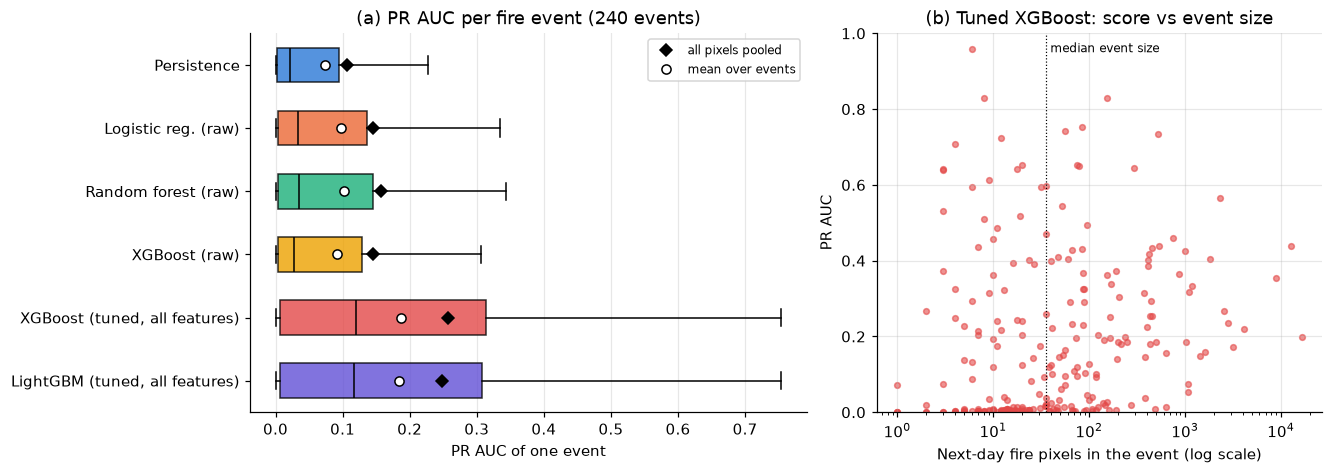

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.25, 1]}, layout="constrained")
names = list(MODELS)
pos = np.arange(1, len(names) + 1)       # one row per model

# (a) spread of per-event PR AUC for each model (box = middle 50% of events, line = median);
#     the black diamond is the usual pixel-pooled PR AUC from results.csv.
bp = axes[0].boxplot([per_event[m]["pr_auc"] for m in names], positions=pos, vert=False, widths=0.55,
                     patch_artist=True, showfliers=False, medianprops={"color": "black"})
for box, m in zip(bp["boxes"], names):
    box.set(facecolor=COLORS[m], alpha=0.8)
axes[0].plot(results.loc[names, "pr_auc"], pos, "D", color="black", ms=6, label="all pixels pooled")
axes[0].plot([per_event[m]["pr_auc"].mean() for m in names], pos, "o", color="white", mec="black", ms=6,
             label="mean over events")
axes[0].set_yticks(pos, [MODELS[m] for m in names])
axes[0].invert_yaxis()                   # first model on top
axes[0].set(xlabel="PR AUC of one event", title=f"(a) PR AUC per fire event ({n_scored} events)")
axes[0].grid(axis="y", visible=False)
axes[0].legend(fontsize=8, loc="upper right")

# (b) is the score different for small and large fires? tuned XGBoost, one dot per event
s = per_event["xgboost"]
axes[1].scatter(s["fire_px"], s["pr_auc"], s=14, alpha=0.6, color=COLORS["xgboost"])
axes[1].axvline(median_fire, color="black", lw=0.8, ls=":")
axes[1].text(median_fire * 1.1, 0.95, "median event size", fontsize=8)
axes[1].set(xscale="log", ylim=(0, 1), xlabel="Next-day fire pixels in the event (log scale)", ylabel="PR AUC",
            title="(b) Tuned XGBoost: score vs event size")
fig.savefig(FIGS / "eval_event_level.png")
plt.show()

**What the event-level scores show**
- The test split is dominated by a few large fires: 1,689 patches are only **257 places**, and the 10 largest
  hold 39% of the patches and 57% of the next-day fire pixels. Pixel-pooled metrics mostly measure these fires.
- Scored per event, every model drops (tuned XGBoost 0.256 → mean 0.187, median 0.120), but the **ranking does not change**:
  the tuned models are still about twice as good as every baseline (raw models 0.09-0.10, persistence 0.07).
  So the main conclusion of Tasks 1-2 holds when every fire counts once.
- The median event is much harder than the mean: in half the events PR AUC is below 0.12. Small fires (≤ 36 next-day
  fire pixels) score lower (0.16) than large ones (0.22), since a small fire gives the model little neighbourhood signal.
- At the eval-chosen threshold the tuned XGBoost finds at least one fire pixel in only 48% of events, fewer than
  persistence (61%). The threshold (0.915) was picked to maximise F1 over pooled pixels, i.e. mostly for the large fires;
  in small fires no pixel reaches it. A threshold chosen per event, or on event-level F1, would be fairer to small fires.
- For Phase 2 the same grouping can be used to report event-level metrics for the CNN, so both phases are compared the same way.